# Analysis of silhouette-based metrics

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc
from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math
from tqdm import tqdm
import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

In [3]:
df_full = pd.read_csv('../results/spreadsheets/metric_values_v14.csv', index_col=0)
df_full = df_full[df_full['Dataset'] != 'human_liver_time']
pivoted_df = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')

runs = pd.read_csv('../results/spreadsheets/all_integrations.csv', index_col=0)

In [4]:
dataset_keys = {

    "scib_sim1": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },

    "scib_sim2": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },

    "human_pancreas": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["tech"]
    },

    "human_lung": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },

    "neurips_bmmc": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },

    "seurat_pbmc": {
        "celltype_keys": ["celltype.l2"],
        "batch_keys": ["donor"]
    },

    "human_brain_cell_atlas": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id", "ROIGroup"]
    },

    "human_fetal_gut": {
        "celltype_keys": ["cell_name_detailed"],
        "batch_keys": ["Donor_id", "Organ", "Sample"]
    },

    "human_liver_time": {
        "celltype_keys": ["time"],
        "batch_keys": ["batch"]
    },

    "pan_cancer_dc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["dataset_id", "cancer_type"]
    },

    "human_eoe": {
        "celltype_keys": ["cell_type_anno"],
        "batch_keys": ["donor_id"]
    },

    "pan_cancer_b": {
        "celltype_keys": ["clusters"],
        "batch_keys": ["study"]
    },

    "human_retina_organoid_tissue": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["sample_id", "tissue"]
    },

    "mouse_regulatory_T": {
        "celltype_keys": ["cell.type"],
        "batch_keys": ["method", "orig.ident"]
    },

    "human_adipose": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["technology", "individual"]
    },

    "tian_multitech": {
        "celltype_keys": ["cell_line"],
        "batch_keys": ["tech"]
    },

    "nph_liver": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },

    "nph_cerebellum": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },

    "tabula_muris_lung": {
        "celltype_keys": ["cell_ontology_id"],
        "batch_keys": ["mouse.id", "tech"]
    },

    "human_pbmc_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },

    "mouse_retina": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["dataset"]
    },

    "mouse_mammary": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },

    "macaque_retina": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },

    "human_heart": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["DonorID", "Tissue"]
    },
    
    "mouse_cortex_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "jurkat_293t": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["dataset"]
    },
    "3_5_pbmc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    },
    "cellranger_versions": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    }
}


## To what extent are cell "clusters" non-spherical

Defined three different metrics of sphericity:

1. Isotropy ratio: after SVD, take the ratio of the smallest and largest singular value.
2. Normalized average singular value: after SVD, normalize all singular values by the largest and take the mean.
3. Effective rank: after SVD, normalize all singular values to form a probability distribution. Then, take the entropy of the distribution and exponentiate it.

In [13]:
spherical = []
for ind, d in tqdm(runs.iterrows()):
    if d['integration'] == 'scmerge-1' and (d['dataset'] == 'human_eoe' or d['dataset'] == 'human_fetal_gut'):
        continue
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = dataset_keys[d['dataset']]['batch_keys'][0]
    celltype_col = dataset_keys[d['dataset']]['celltype_keys'][0]

    for ct in adata_int.obs[celltype_col].unique():
        adata_sub = adata_int[adata_int.obs[celltype_col] == ct]
        
        X = adata_sub.obsm['X_integration']
        X = X - X.mean(axis=0, keepdims=True)
        s_values = np.linalg.svd(X, compute_uv=False)

        isotropy_ratio = s_values.min() / s_values.max()
        isotropy_ratio1 = (s_values / s_values.max()).mean()  # Normalized average singular value
        effective_rank = np.exp(scipy.stats.entropy(s_values / s_values.max())) / X.shape[1]

        spherical.append((d['integration'], d['dataset'], ct, isotropy_ratio, isotropy_ratio1, effective_rank) )

898it [2:02:29,  8.18s/it] 


In [44]:
# This is a random uniform control embedding of the same size
control = []
for ind, d in dirs.iterrows():
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = adata_int.obs.columns[0]
    celltype_col = adata_int.obs.columns[-11]

    for ct in adata_int.obs[celltype_col].unique():
        np.random.seed(0)
        adata_sub = adata_int[adata_int.obs[celltype_col] == ct]
        A = np.random.randn(*adata_sub.obsm['X_integration'].shape)
        s_values = np.linalg.svd(A, compute_uv=False)

        cond_number = np.linalg.cond(A)

        control.append((d['integration'], ct, isotropy_ratio, cond_number) )

In [45]:
control_df = pd.DataFrame(control, columns=['Integration', 'Cell type', 'Isotropy', 'Condition'])

In [47]:
control_df[control_df.Integration == 'scvi-1']

,Integration,Cell type,Isotropy,Condition
14,scvi-1,gamma,0.821587,1.217156
15,scvi-1,acinar,0.852335,1.173248
16,scvi-1,alpha,0.929003,1.076423
17,scvi-1,delta,0.847761,1.179577
18,scvi-1,beta,0.917265,1.090197
19,scvi-1,ductal,0.890643,1.122785
20,scvi-1,endothelial,0.730354,1.369200
21,scvi-1,activated_stellate,0.770759,1.297422
22,scvi-1,schwann,0.265423,3.767566
23,scvi-1,mast,0.363011,2.754737


In [14]:
spherical_df = pd.DataFrame(spherical, columns=['Integration', 'Dataset', 'Cell type', 'Isotropy', 'Isotropy Alt', 'Effective Rank'])

In [15]:
spherical_df.to_csv('../results/spreadsheets/sphericalness_new.csv', index=False)

## Correlate sphericity with CASW performance

`Isotropy Alt` can be replaced with `Isotropy` to get results for the first measure of sphericity.

In [45]:
spherical_df = pd.read_csv('../results/spreadsheets/sphericalness_new.csv')
spherical_df = spherical_df[spherical_df['Dataset'] != 'human_liver_time']  # Bad dataset

In [47]:
sphericalness = spherical_df.groupby(['Integration', 'Dataset'])['Isotropy Alt'].mean().reset_index().rename(columns={'Isotropy Alt': "Value"})
sphericalness['Metric'] = 'sphericalness'

In [52]:
sub = df_full[(df_full.Metric.isin(['casw', 'bami', 'clisi']))]
sub = pd.concat([sub, sphericalness]).reset_index(drop=True)

sub = sub.pivot(index=['Integration', 'Dataset'], columns='Metric', values='Value').reset_index()
sub = sub[~sub['bami'].isna()]
sub = sub[~sub['clisi'].isna()]

sub = sub[~sub['sphericalness'].isna()]
len(sub)

791

In [56]:
# Either comment or uncomment this line to remove the baselines
# gained from drawing from Gaussian distributions.
sub = sub[~sub['Integration'].isin(['oneBigBlob-1', 'equidistant-1'])]

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each predictor
X = sub[['bami', 'clisi', 'sphericalness']]
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

         feature        VIF
0           bami  21.430185
1          clisi  22.182482
2  sphericalness   3.059330


In [58]:
import statsmodels.api as sm

X = sub[[ 'bami', 'clisi', 'sphericalness']]
X = sm.add_constant(X) 
y = sub['casw']
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   casw   R-squared:                       0.378
Model:                            OLS   Adj. R-squared:                  0.376
Method:                 Least Squares   F-statistic:                     149.4
Date:                Mon, 21 Sep 2026   Prob (F-statistic):           1.26e-75
Time:                        14:21:38   Log-Likelihood:                 785.68
No. Observations:                 741   AIC:                            -1563.
Df Residuals:                     737   BIC:                            -1545.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.5159      0.039     13.216

## To what extent are batches spherical?

To match the use of BRAS, we calculate per-batch per-cell-type sphericity.

In [102]:
from tqdm import tqdm

spherical = []
for ind, d in tqdm(runs.iterrows()):
    if d['integration'] == 'scmerge-1' and (d['dataset'] == 'human_eoe' or d['dataset'] == 'human_fetal_gut'):
        continue
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = dataset_keys[d['dataset']]['batch_keys'][0]
    celltype_col = dataset_keys[d['dataset']]['celltype_keys'][0]

    for ct in adata_int.obs[celltype_col].unique():
        adata_sub = adata_int[adata_int.obs[celltype_col] == ct]
        
        if len(np.unique(adata_sub.obs[batch_col])) == 1:
            continue
            
        for batch in np.unique(adata_sub.obs[batch_col]):
            sub_sub = adata_sub[adata_sub.obs[batch_col] == batch]
            if sub_sub.n_obs < 10:
                continue
            X = sub_sub.obsm['X_integration']
            X = X - X.mean(axis=0, keepdims=True)
            s_values = np.linalg.svd(X, compute_uv=False)

            isotropy_ratio = s_values.min() / s_values.max()
            isotropy_ratio1 = (s_values / s_values.max()).mean()
            effective_rank = np.exp(scipy.stats.entropy(s_values / s_values.max())) / X.shape[1]

            spherical.append((d['integration'], d['dataset'], ct, batch, isotropy_ratio, isotropy_ratio1, effective_rank) )

48it [01:03,  3.20s/it]/tmp/ipykernel_662289/1639388972.py:25: RuntimeWarning: invalid value encountered in scalar divide
  isotropy_ratio = s_values.min() / s_values.max()
/tmp/ipykernel_662289/1639388972.py:26: RuntimeWarning: invalid value encountered in divide
  isotropy_ratio1 = (s_values / s_values.max()).mean()
/tmp/ipykernel_662289/1639388972.py:27: RuntimeWarning: invalid value encountered in divide
  effective_rank = np.exp(scipy.stats.entropy(s_values / s_values.max())) / X.shape[1]
795it [4:58:16, 349.39s/it]/tmp/ipykernel_662289/1639388972.py:25: RuntimeWarning: invalid value encountered in scalar divide
  isotropy_ratio = s_values.min() / s_values.max()
/tmp/ipykernel_662289/1639388972.py:26: RuntimeWarning: invalid value encountered in divide
  isotropy_ratio1 = (s_values / s_values.max()).mean()
/tmp/ipykernel_662289/1639388972.py:27: RuntimeWarning: invalid value encountered in divide
  effective_rank = np.exp(scipy.stats.entropy(s_values / s_values.max())) / X.shape[1

In [104]:
spherical_df = pd.DataFrame(spherical, columns=['Integration', 'Dataset', 'Cell type', 'Batch', 'Isotropy', "Isotropy Alt", 'Effective Rank'])

In [105]:
spherical_df.to_csv('../results/spreadsheets/sphericalness_batch_new.csv', index=False)

## Correlate sphericity with BRAS and BASW

In [145]:
spherical_df = pd.read_csv('../results/spreadsheets/sphericalness_batch_new.csv')
spherical_df = spherical_df[spherical_df['Dataset'] != 'human_liver_time']  # Bad dataset

In [162]:
sphericalness = spherical_df.groupby(['Integration', 'Dataset'])['Isotropy'].mean().reset_index().rename(columns={'Isotropy': "Value"})
sphericalness['Metric'] = 'sphericalness'

In [163]:
sub = df_full[(df_full.Metric.isin(['basw', 'bras', 'kbet', 'probe']))]
sub = pd.concat([sub, sphericalness]).reset_index(drop=True)

In [164]:
# Either comment or uncomment this line to remove the baselines
# gained from drawing from Gaussian distributions.
# sub = sub[~sub.Integration.isin(['oneBigBlob-1', 'equidistant-1'])]

In [165]:
sub = sub.pivot(index=['Integration', 'Dataset'], columns='Metric', values='Value').reset_index()
sub = sub[~sub['basw'].isna()]
sub = sub[~sub['bras'].isna()]
sub = sub[~sub['kbet'].isna()]
sub = sub[~sub['probe'].isna()]
sub = sub[~sub['sphericalness'].isna()]
len(sub)

802

In [166]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each predictor
X = sub[['kbet', 'probe', 'sphericalness']]
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

         feature       VIF
0           kbet  3.153862
1          probe  3.403743
2  sphericalness  2.174158


In [167]:
import statsmodels.api as sm

# 1. Prepare features (add a constant for the intercept)
X = sub[[ 'kbet', 'probe', 'sphericalness']]
X = sm.add_constant(X) 
y = sub['bras']

# 2. Fit the OLS model
model = sm.OLS(y, X).fit()

# 3. View the results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   bras   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.407
Method:                 Least Squares   F-statistic:                     184.4
Date:                Mon, 21 Sep 2026   Prob (F-statistic):           7.80e-91
Time:                        20:41:29   Log-Likelihood:                 459.17
No. Observations:                 802   AIC:                            -910.3
Df Residuals:                     798   BIC:                            -891.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.5493      0.010     54.480

## Sphericalness plots

In [80]:
sphericalness = spherical_df.groupby(['Integration', 'Dataset'])['Isotropy'].mean().reset_index().rename(columns={'Isotropy': "Value"})
sphericalness['Metric'] = 'sphericalness'

In [86]:
sub = df_full[(df_full.Metric.isin(['kbet', 'bcent', 'bras']))]
sub = pd.concat([sub, sphericalness]).reset_index(drop=True)

In [87]:
sub = sub.pivot(index=['Integration', 'Dataset'], columns='Metric', values='Value').reset_index()
sub = sub[~sub['kbet'].isna()]
sub = sub[~sub['bcent'].isna()]
sub = sub[~sub['bras'].isna()]
sub = sub[~sub['sphericalness'].isna()]

In [88]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each predictor
X = sub[['kbet', 'bcent', 'sphericalness']]
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

         feature       VIF
0           kbet  3.565263
1          bcent  3.117851
2  sphericalness  1.440679


In [91]:
import statsmodels.api as sm

# 1. Prepare features (add a constant for the intercept)
X = sub[[ 'kbet', 'sphericalness']]
X = sm.add_constant(X) 
y = sub['bras']

# 2. Fit the OLS model
model = sm.OLS(y, X).fit()

# 3. View the results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   bras   R-squared:                       0.307
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     176.8
Date:                Tue, 21 Apr 2026   Prob (F-statistic):           2.88e-64
Time:                        21:03:59   Log-Likelihood:                 393.50
No. Observations:                 800   AIC:                            -781.0
Df Residuals:                     797   BIC:                            -766.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.6100      0.009     66.449

## Sphericity plots

In [9]:
spherical_df = pd.read_csv('../results/spreadsheets/sphericalness_new.csv')
spherical_df = spherical_df[spherical_df['Dataset'] != 'human_liver_time']  # Bad dataset
spherical_df['Dataset'] = spherical_df['Dataset'].replace({
    'nph_cerebellum': "nhp_cerebellum", 'nph_liver': "nhp_liver"
})

In [10]:
sphericalness = spherical_df.groupby(['Integration', 'Dataset'])['Isotropy'].mean().reset_index().rename(columns={'Isotropy': "Value"})
sphericalness['Metric'] = 'sphericalness'

In [11]:
sub = df_full[(df_full.Metric.isin(['casw', 'bami', 'clisi']))]
sub = pd.concat([sub, sphericalness]).reset_index(drop=True)

sub = sub.pivot(index=['Integration', 'Dataset'], columns='Metric', values='Value').reset_index()
sub = sub[~sub['bami'].isna()]
sub = sub[~sub['clisi'].isna()]

sub = sub[~sub['sphericalness'].isna()]
len(sub)

729

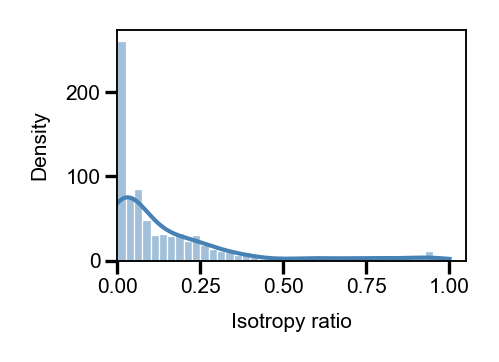

In [90]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(1.5, 1))

    sns.histplot(
        sub['sphericalness'], 
        bins=40, 
        kde=True, 
        ax=ax, 
        color='steelblue',
        edgecolor='white',
        linewidth=0.3,
        line_kws={'linewidth': 1}
    )

    plt.xlabel("Isotropy ratio", fontsize=5)
    plt.ylabel('Density', fontsize=5)
    plt.xlim(0, None)

    ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
#     plt.savefig('../publication_figures/isotropy_density.png', dpi=300, bbox_inches='tight')
    plt.show()

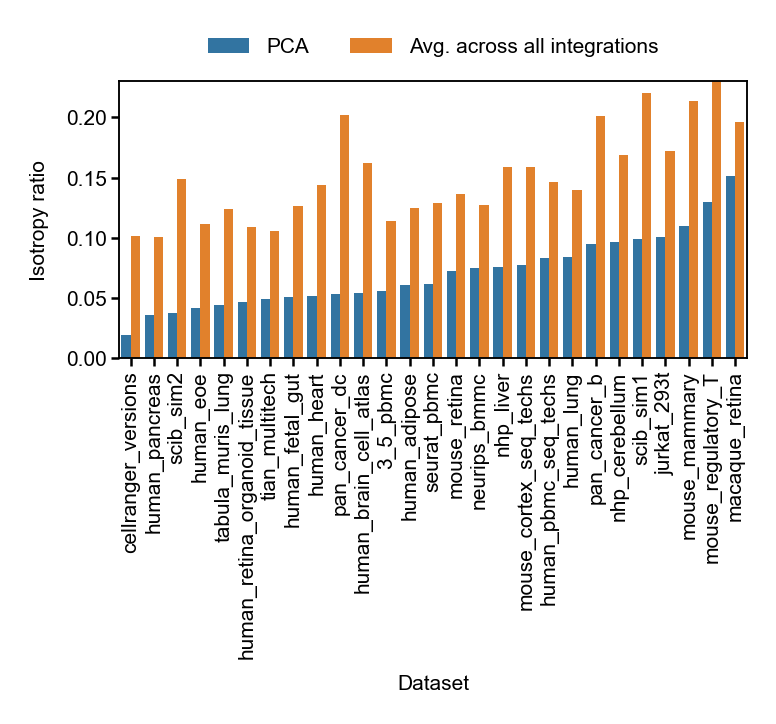

In [12]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(2.7, 1.2))
    p = sphericalness[sphericalness['Integration'] == 'pca-1'].sort_values('Value')
    p = p.set_index('Dataset').join(
        sphericalness.groupby('Dataset')['Value'].agg(lambda x: x.mean(skipna=False)), rsuffix='_1')
    p.index = p.index.str.replace('sequencing', 'seq')

    p_melted = p[['Value', 'Value_1']].reset_index().melt(
        id_vars='Dataset',
        value_vars=['Value', 'Value_1'],
        var_name='Type',
        value_name='Score'
    )
    p_melted['Type'] = p_melted['Type'].replace({'Value': 'PCA', 'Value_1': "Avg. across all integrations"})

    sns.barplot(
        data=p_melted,
        x='Dataset', y='Score', hue='Type',
        ax=ax
    )
    ax.tick_params(axis='both', which='major', width=.6, length=2, labelsize=5, pad=1)
    plt.xticks(rotation=90)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.set_ylabel('Isotropy ratio', fontsize=5)
    ax.set_xlabel('Dataset', fontsize=5)
    ax.set_ylim(0, 0.23)
    ax.legend(
        fontsize=5, title_fontsize=4, frameon=False, ncols=2,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02)
    )
#     plt.savefig('../publication_figures/isotropy_datasets.png', dpi=300, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_662289/3785075558.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=5, title_fontsize=4, frameon=False)


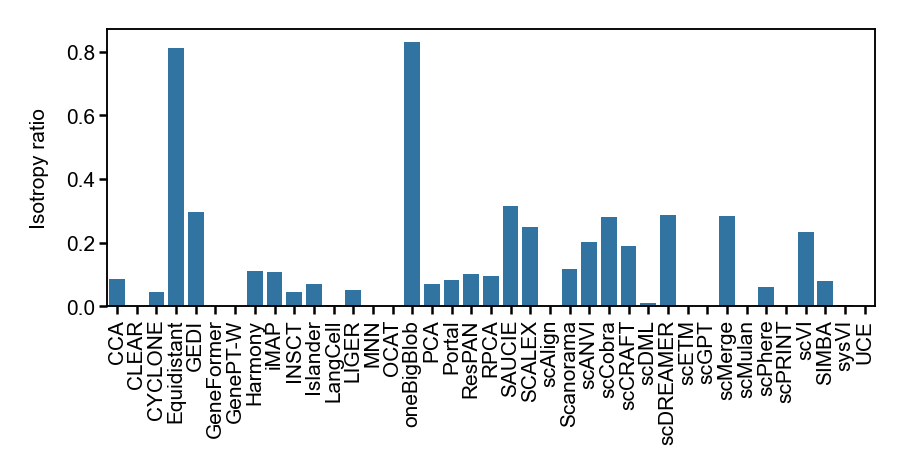

In [89]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(3.3, 1.2))
    p = sphericalness.groupby('Integration')['Value'].agg(lambda x: x.mean(skipna=False))
    p.index = p.index.str[:-2]
    data = p.reset_index()
    data['Integration'] = data['Integration'].replace(NAME_MAP)
    sns.barplot(
        data=data,
        x='Integration', y='Value',
        ax=ax
    )
    ax.tick_params(axis='both', which='major', width=.6, length=2, labelsize=5, pad=1)
    plt.xticks(rotation=90)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.set_ylabel('Isotropy ratio', fontsize=5)
    ax.set_xlabel('', fontsize=5)
    ax.set_ylim(0, None)
    ax.legend(fontsize=5, title_fontsize=4, frameon=False)
#     plt.savefig('../publication_figures/isotropy_methods.png', dpi=300, bbox_inches='tight')
    plt.show()

In [91]:
spherical_df = pd.read_csv('../results/spreadsheets/sphericalness_new.csv')
spherical_df = spherical_df[spherical_df['Dataset'] != 'human_liver_time']  # Bad dataset

In [92]:
sphericalness = spherical_df.groupby(['Integration', 'Dataset'])['Isotropy Alt'].mean().reset_index().rename(columns={'Isotropy Alt': "Value"})
sphericalness['Metric'] = 'sphericalness'

In [93]:
sub = df_full[(df_full.Metric.isin(['casw', 'bami', 'clisi']))]
sub = pd.concat([sub, sphericalness]).reset_index(drop=True)

sub = sub.pivot(index=['Integration', 'Dataset'], columns='Metric', values='Value').reset_index()
sub = sub[~sub['bami'].isna()]
sub = sub[~sub['clisi'].isna()]

sub = sub[~sub['sphericalness'].isna()]
len(sub)

791

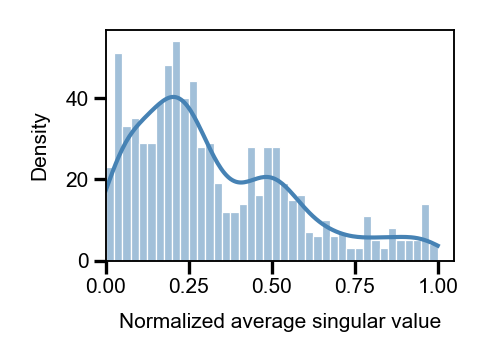

In [94]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(1.5, 1))

    sns.histplot(
        sub['sphericalness'], 
        bins=40, 
        kde=True, 
        ax=ax, 
        color='steelblue',
        edgecolor='white',
        linewidth=0.3,
        line_kws={'linewidth': 1}
    )

    plt.xlabel('Normalized average singular value', fontsize=5)
    plt.ylabel('Density', fontsize=5)
    plt.xlim(0, None)

    ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
#     plt.savefig('../publication_figures/sphericalness_density.png', dpi=300, bbox_inches='tight')
    plt.show()

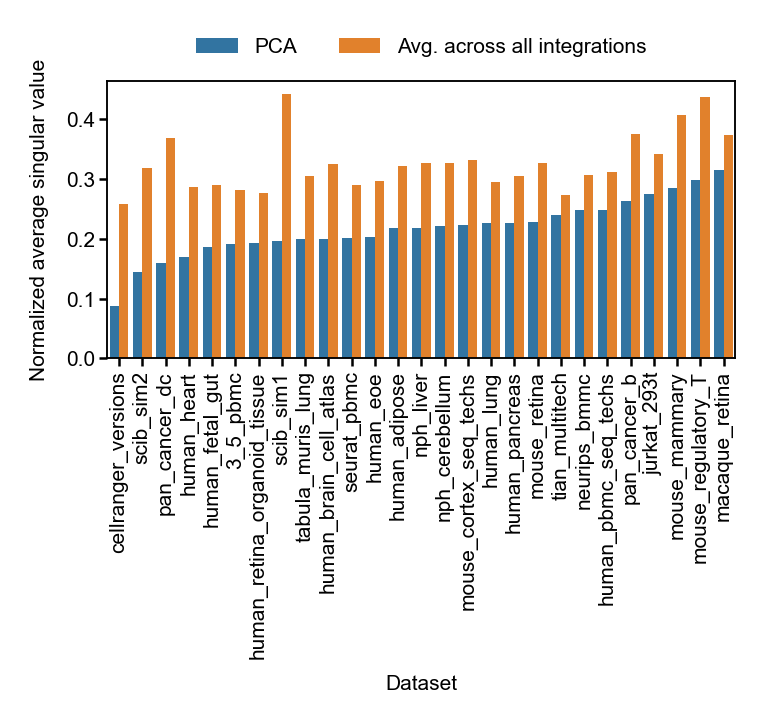

In [95]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(2.7, 1.2))
    p = sphericalness[sphericalness['Integration'] == 'pca-1'].sort_values('Value')
    p = p.set_index('Dataset').join(
        sphericalness.groupby('Dataset')['Value'].agg(lambda x: x.mean(skipna=False)), rsuffix='_1')
    p.index = p.index.str.replace('sequencing', 'seq')

    p_melted = p[['Value', 'Value_1']].reset_index().melt(
        id_vars='Dataset',
        value_vars=['Value', 'Value_1'],
        var_name='Type',
        value_name='Score'
    )
    p_melted['Type'] = p_melted['Type'].replace({'Value': 'PCA', 'Value_1': "Avg. across all integrations"})

    sns.barplot(
        data=p_melted,
        x='Dataset', y='Score', hue='Type',
        ax=ax
    )
    ax.tick_params(axis='both', which='major', width=.6, length=2, labelsize=5, pad=1)
    plt.xticks(rotation=90)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.set_ylabel('Normalized average singular value', fontsize=5)
    ax.set_xlabel('Dataset', fontsize=5)
    ax.set_ylim(0, None)
    ax.legend(
        fontsize=5, title_fontsize=4, frameon=False, ncols=2,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02)
    )
#     plt.savefig('../publication_figures/sphericalness_datasets.png', dpi=300, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_662289/1488409327.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=5, title_fontsize=4, frameon=False)


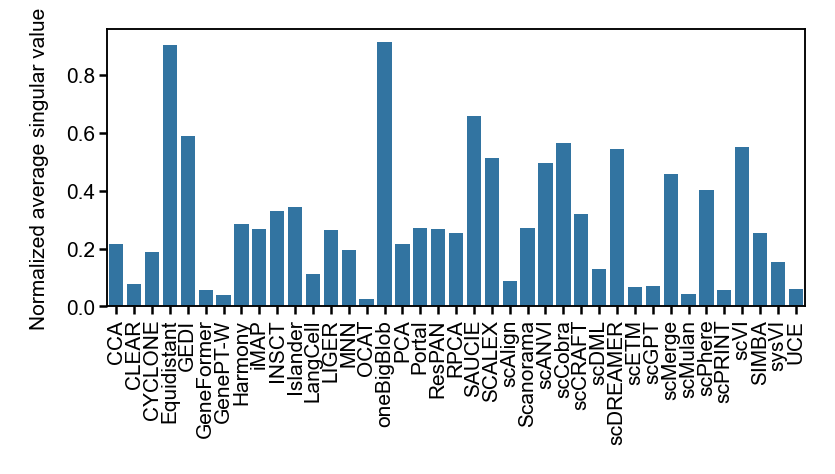

In [96]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = plt.subplots(figsize=(3, 1.2))
    p = sphericalness.groupby('Integration')['Value'].agg(lambda x: x.mean(skipna=False))
    p.index = p.index.str[:-2]
    data = p.reset_index()
    data['Integration'] = data['Integration'].replace(NAME_MAP)
    sns.barplot(
        data=data,
        x='Integration', y='Value',
        ax=ax
    )
    ax.tick_params(axis='both', which='major', width=.6, length=2, labelsize=5, pad=1)
    plt.xticks(rotation=90)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.set_ylabel('Normalized average singular value', fontsize=5)
    ax.set_xlabel('', fontsize=5)
    ax.set_ylim(0, None)
    ax.legend(fontsize=5, title_fontsize=4, frameon=False)
#     plt.savefig('../publication_figures/sphericalness_methods.png', dpi=300, bbox_inches='tight')
    plt.show()

## BRAS as a medium-granularity metric

Use the scIB simulation data 2 for exposition, using the Scanorama and scVI integrations as examples.

In [42]:
d = runs[runs.name.str.contains('scib_sim2') & runs.name.str.contains('scanorama')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

adata_int

AnnData object with n_obs × n_vars = 19318 × 2000
    obs: 'Batch', 'Group', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    obsp: 'connectivities', 'distances'

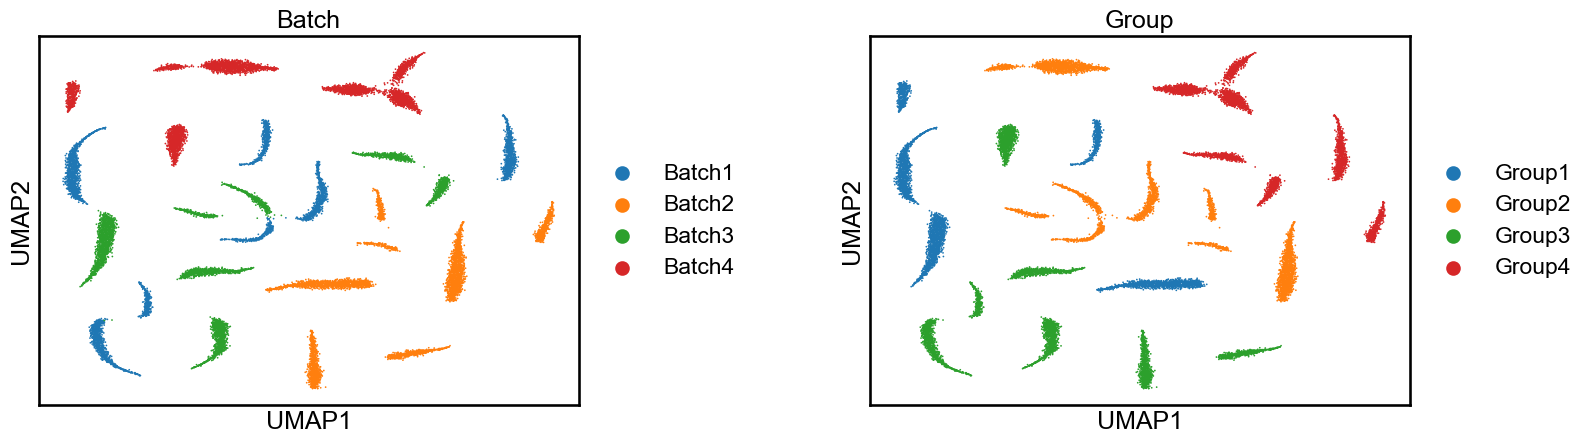

In [44]:
sc.pl.umap(adata_int, color=[batch_col, celltype_col], ncols=2, wspace=0.4)